# Iris Flower Classification

## Project overview

In this project, I use the Iris measurements already provided in the workspace to predict a flower's species. I compare two familiar classification methods?Logistic Regression and a Decision Tree?and evaluate them on observations not used to fit the models.

**Project question:** How accurately can sepal and petal measurements distinguish the three species in this dataset?

**Dataset:** The existing project CSV has four numeric measurements and a categorical species label. This notebook reads that file with Pandas and leaves the original CSV unchanged. It does not use Scikit-learn's built-in Iris dataset.

**Workflow:** inspect the data ? explore class and feature patterns ? split the data ? preprocess using training data ? train both classifiers ? compare test metrics and errors ? visualize two-feature decision boundaries.

**Evaluation:** Accuracy measures overall correctness. Precision, recall, F1-score, and confusion matrices add class-level detail. A fixed random seed makes the split repeatable.

## 1. Import libraries

These libraries cover data inspection, plotting, preprocessing, model training, and evaluation. I keep this section together so the notebook's dependencies are easy to review.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_selection import f_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 2. Load the existing dataset

The CSV already included in the project is the only data source. Pandas reads it into a DataFrame; the source file is not edited. The printed path and preview help confirm that the intended file was loaded.

In [3]:
# The notebook may be run from either the project root or Dataset folder.
candidates = [
    Path("iris.csv"),
    Path("task 1") / "iris.csv",
    Path.cwd().parent / "Task 1" / "iris.csv",
]
dataset_path = next((path.resolve() for path in candidates if path.is_file()), None)
if dataset_path is None:
    raise FileNotFoundError(
        "Could not find the existing Task 1/iris.csv. Run this notebook from the project root or Dataset folder."
    )

df = pd.read_csv(dataset_path)
print(f"Dataset path: {dataset_path}")
print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}")
print("\nFirst five rows:")
print(df.head().to_string(index=False))

Dataset path: C:\Users\usms.202300087\Datheon_Machine_Learning_&_Data_Science_Internship\Task 1\iris.csv
Rows: 150 | Columns: 5

First five rows:
 sepal_length  sepal_width  petal_length  petal_width species
          5.1          3.5           1.4          0.2  setosa
          4.9          3.0           1.4          0.2  setosa
          4.7          3.2           1.3          0.2  setosa
          4.6          3.1           1.5          0.2  setosa
          5.0          3.6           1.4          0.2  setosa


## 3. Identify the target column

A supervised classifier needs a label to predict. This step looks for one unambiguous categorical column with several classes. If the dataset structure changes and that rule is ambiguous, the notebook stops rather than silently choosing a target.

In [4]:
# Find a single categorical column with more than one class. Stop for review if ambiguous.
category_limit = max(20, int(0.2 * len(df)))
target_candidates = [
    column
    for column in df.columns
    if (
        pd.api.types.is_object_dtype(df[column])
        or pd.api.types.is_string_dtype(df[column])
        or pd.api.types.is_bool_dtype(df[column])
    )
    and 1 < df[column].nunique(dropna=True) <= category_limit
]
if len(target_candidates) != 1:
    raise ValueError(f"Expected one categorical target column; found: {target_candidates}")

target = target_candidates[0]
print(f"Target/class column: {target}")
print(f"Classes: {sorted(df[target].dropna().astype(str).unique())}")

Target/class column: species
Classes: ['setosa', 'versicolor', 'virginica']


## 4. Inspect columns and data types

Checking the feature names and types helps confirm which columns can be used as measurements and whether any values need conversion before modeling.

In [5]:
print("Column names and data types:")
for column, dtype in df.dtypes.items():
    print(f"- {column}: {dtype}")

print(f"\nDataset shape: {df.shape}")
print(f"\nDuplicate rows: {df.duplicated().sum()}")

Column names and data types:
- sepal_length: float64
- sepal_width: float64
- petal_length: float64
- petal_width: float64
- species: str

Dataset shape: (150, 5)

Duplicate rows: 1


## 5. Check missing values

Missing data can affect model fitting. I check each column first; the later preprocessing step imputes numeric values using statistics learned from the training set only.

In [6]:
missing_values = df.isna().sum()
print("Missing values in each column:")
print(missing_values.to_string())
print(f"\nTotal missing values: {missing_values.sum()}")

Missing values in each column:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0

Total missing values: 0


## 6. Review summary statistics

The summary gives a quick view of feature ranges and spread. Differences in measurement scale are one reason to standardize numeric inputs for Logistic Regression.

In [7]:
numeric_columns = df.drop(columns=target).select_dtypes(include=np.number).columns.tolist()
print("Summary statistics for numeric features:")
print(df[numeric_columns].describe().round(2).to_string())

Summary statistics for numeric features:
       sepal_length  sepal_width  petal_length  petal_width
count        150.00       150.00        150.00       150.00
mean           5.84         3.06          3.76         1.20
std            0.83         0.44          1.77         0.76
min            4.30         2.00          1.00         0.10
25%            5.10         2.80          1.60         0.30
50%            5.80         3.00          4.35         1.30
75%            6.40         3.30          5.10         1.80
max            7.90         4.40          6.90         2.50


## 7. Explore class counts

Class counts show whether the target groups are balanced. Here, stratified splitting can preserve each class's share in both train and test data.

In [8]:
class_counts = df[target].value_counts(dropna=False)
print("Number of rows in each class:")
print(class_counts.to_string())

Number of rows in each class:
species
setosa        50
versicolor    50
virginica     50


## 8. Visualize the class distribution

This bar chart makes class balance easier to see than a table alone. It also provides context for interpreting accuracy and the per-class metrics later.

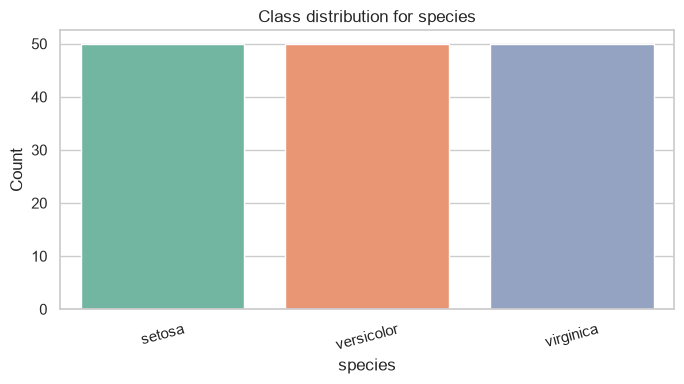

In [9]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x=target, hue=target, legend=False, palette="Set2")
plt.title(f"Class distribution for {target}")
plt.xlabel(target)
plt.ylabel("Count")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 9. Compare numeric features across classes

The boxplots compare the range and median of each measurement across species. Features with visibly different distributions may help separate classes, though the plot alone does not establish predictive performance.

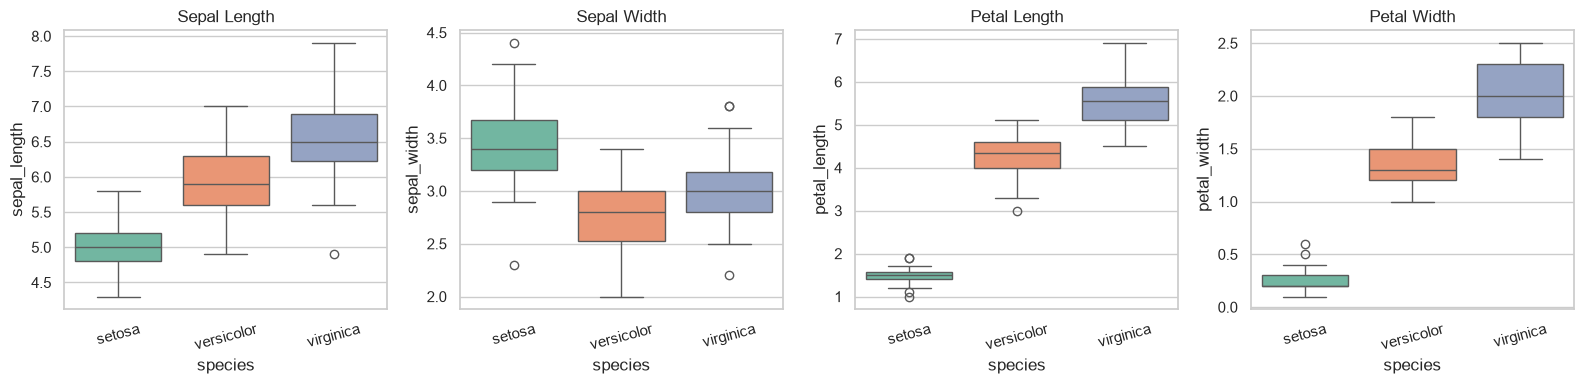

In [10]:
fig, axes = plt.subplots(1, len(numeric_columns), figsize=(4 * len(numeric_columns), 4))
for ax, feature in zip(np.atleast_1d(axes), numeric_columns):
    sns.boxplot(data=df, x=target, y=feature, hue=target, legend=False, palette="Set2", ax=ax)
    ax.set_title(feature.replace("_", " ").title())
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

## 10. Examine correlations between numeric features

Correlation indicates linear association between pairs of numeric measurements. It is useful for understanding overlap or redundancy, but it does not imply causation and does not by itself determine which classifier is best.

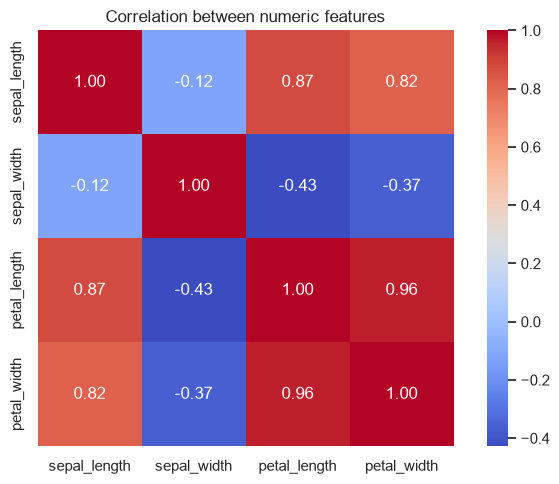

In [11]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[numeric_columns].corr(), annot=True, cmap="coolwarm", fmt=".2f", square=True)
plt.title("Correlation between numeric features")
plt.tight_layout()
plt.show()

## 11. Prepare features and target

The feature matrix contains the measurements, while the target series contains the species labels. Rows without a known label cannot be used for supervised training, so they are excluded from this modeling copy.

In [12]:
# Rows without a known class cannot be used for supervised training.
model_df = df.dropna(subset=[target]).copy()
X = model_df.drop(columns=target)
y = model_df[target].astype(str)

print(f"Feature matrix shape: {X.shape}")
print(f"Target length: {len(y)}")
print(f"Feature columns: {X.columns.tolist()}")

Feature matrix shape: (150, 4)
Target length: 150
Feature columns: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']


## 12. Split into training and test sets

The 80/20 split keeps a portion of the labeled observations unseen during fitting. Stratification preserves the class proportions, and the fixed random seed makes this experiment reproducible.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Training rows: {len(X_train)} ({len(X_train) / len(X):.0%})")
print(f"Test rows: {len(X_test)} ({len(X_test) / len(X):.0%})")
print("\nTraining class counts:")
print(y_train.value_counts().sort_index().to_string())
print("\nTest class counts:")
print(y_test.value_counts().sort_index().to_string())

Training rows: 120 (80%)
Test rows: 30 (20%)

Training class counts:
species
setosa        40
versicolor    40
virginica     40

Test class counts:
species
setosa        10
versicolor    10
virginica     10


## 13. Impute and scale numeric features

The imputer and scaler are fitted on the training data, then applied to the test data. This prevents information from the test set influencing preprocessing. Standardization is especially useful for Logistic Regression; the Decision Tree is trained separately on imputed, unscaled measurements.

In [14]:
# Fit preprocessing on training features only to avoid leaking test-set information.
if not all(pd.api.types.is_numeric_dtype(X_train[column]) for column in X_train.columns):
    raise ValueError("This notebook's scaling step expects numeric feature columns. Review and encode categorical features first.")

imputer = SimpleImputer(strategy="median")
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print(f"Training matrix after preprocessing: {X_train_scaled.shape}")
print(f"Test matrix after preprocessing: {X_test_scaled.shape}")
print("Missing numeric values were median-imputed; numeric features were standardized.")

Training matrix after preprocessing: (120, 4)
Test matrix after preprocessing: (30, 4)
Missing numeric values were median-imputed; numeric features were standardized.


## 14. Train Logistic Regression

Logistic Regression is a linear classification baseline. The `max_iter` setting allows the optimizer enough steps to converge on the standardized measurements.

In [15]:
logistic_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
logistic_model.fit(X_train_scaled, y_train)
logistic_predictions = logistic_model.predict(X_test_scaled)
print("Logistic Regression model trained.")

Logistic Regression model trained.


## 15. Evaluate Logistic Regression

Accuracy is the share of correct predictions. Precision, recall, and F1 are reported with weighted averaging so the overall scores account for each class's support; the class-wise report shows where performance differs.

In [16]:
labels = sorted(y.unique())
logistic_accuracy = accuracy_score(y_test, logistic_predictions)
logistic_precision = precision_score(y_test, logistic_predictions, average="weighted", zero_division=0)
logistic_recall = recall_score(y_test, logistic_predictions, average="weighted", zero_division=0)
logistic_f1 = f1_score(y_test, logistic_predictions, average="weighted", zero_division=0)

print(f"Accuracy: {logistic_accuracy:.3f}")
print(f"Weighted precision: {logistic_precision:.3f}")
print(f"Weighted recall: {logistic_recall:.3f}")
print(f"Weighted F1-score: {logistic_f1:.3f}")
print("\nClassification report:")
print(classification_report(y_test, logistic_predictions, labels=labels, zero_division=0))

Accuracy: 0.933
Weighted precision: 0.933
Weighted recall: 0.933
Weighted F1-score: 0.933

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



## 16. Logistic Regression confusion matrix

The confusion matrix compares actual classes (rows) with predicted classes (columns). Diagonal counts are correct predictions; off-diagonal counts identify which species were confused.

Rows are actual classes; columns are predicted classes.
            setosa  versicolor  virginica
setosa          10           0          0
versicolor       0           9          1
virginica        0           1          9


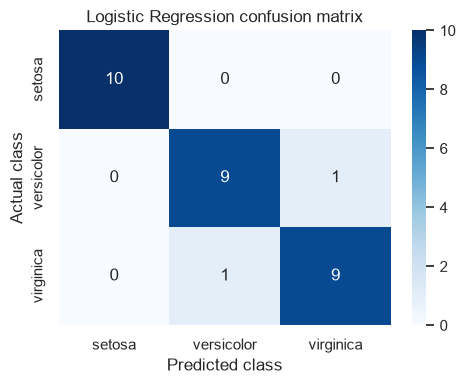

In [17]:
logistic_matrix = confusion_matrix(y_test, logistic_predictions, labels=labels)
print("Rows are actual classes; columns are predicted classes.")
print(pd.DataFrame(logistic_matrix, index=labels, columns=labels).to_string())

plt.figure(figsize=(5, 4))
sns.heatmap(logistic_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title("Logistic Regression confusion matrix")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.tight_layout()
plt.show()

## 17. Train Decision Tree

A Decision Tree learns a sequence of feature-based rules. Unlike Logistic Regression, it does not require feature scaling, so it uses the imputed measurements before standardization.

In [18]:
# A tree does not require feature scaling; use imputed, unscaled numeric features.
decision_tree_model = DecisionTreeClassifier(random_state=RANDOM_STATE)
decision_tree_model.fit(X_train_imputed, y_train)
decision_tree_predictions = decision_tree_model.predict(X_test_imputed)
print("Decision Tree model trained.")

Decision Tree model trained.


## 18. Evaluate Decision Tree

The same held-out observations and metrics are used for a fair comparison with Logistic Regression. The classification report helps distinguish strong overall accuracy from performance on individual species.

In [19]:
tree_accuracy = accuracy_score(y_test, decision_tree_predictions)
tree_precision = precision_score(y_test, decision_tree_predictions, average="weighted", zero_division=0)
tree_recall = recall_score(y_test, decision_tree_predictions, average="weighted", zero_division=0)
tree_f1 = f1_score(y_test, decision_tree_predictions, average="weighted", zero_division=0)

print(f"Accuracy: {tree_accuracy:.3f}")
print(f"Weighted precision: {tree_precision:.3f}")
print(f"Weighted recall: {tree_recall:.3f}")
print(f"Weighted F1-score: {tree_f1:.3f}")
print("\nClassification report:")
print(classification_report(y_test, decision_tree_predictions, labels=labels, zero_division=0))

Accuracy: 0.933
Weighted precision: 0.933
Weighted recall: 0.933
Weighted F1-score: 0.933

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



## 19. Decision Tree confusion matrix

As above, the diagonal represents correct predictions and the off-diagonal entries show mistakes. Comparing this matrix with Logistic Regression's matrix helps explain whether the models make similar errors.

Rows are actual classes; columns are predicted classes.
            setosa  versicolor  virginica
setosa          10           0          0
versicolor       0           9          1
virginica        0           1          9


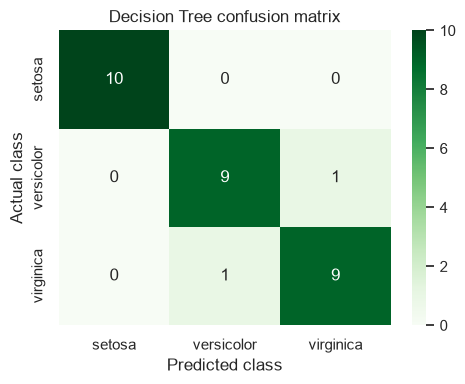

In [20]:
tree_matrix = confusion_matrix(y_test, decision_tree_predictions, labels=labels)
print("Rows are actual classes; columns are predicted classes.")
print(pd.DataFrame(tree_matrix, index=labels, columns=labels).to_string())

plt.figure(figsize=(5, 4))
sns.heatmap(tree_matrix, annot=True, fmt="d", cmap="Greens", xticklabels=labels, yticklabels=labels)
plt.title("Decision Tree confusion matrix")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.tight_layout()
plt.show()

## 20. Compare the models

Both classifiers are evaluated on the same stratified test split. Accuracy summarizes overall correctness, while weighted precision, recall, and F1 provide complementary views. A tie means these metrics do not establish one model as the winner for this split.

In [21]:
print("Held-out test-set results (weighted precision, recall and F1):")
for name, accuracy, precision, recall, f1 in [
    ("Logistic Regression", logistic_accuracy, logistic_precision, logistic_recall, logistic_f1),
    ("Decision Tree", tree_accuracy, tree_precision, tree_recall, tree_f1),
]:
    print(
        f"{name:22} | Accuracy: {accuracy:.3f} | Precision: {precision:.3f} "
        f"| Recall: {recall:.3f} | F1: {f1:.3f}"
    )

Held-out test-set results (weighted precision, recall and F1):
Logistic Regression    | Accuracy: 0.933 | Precision: 0.933 | Recall: 0.933 | F1: 0.933
Decision Tree          | Accuracy: 0.933 | Precision: 0.933 | Recall: 0.933 | F1: 0.933


## 21. Visualize decision boundaries

A two-dimensional boundary plot cannot display all four input measurements. The notebook therefore selects two numeric features using the training portion and fits separate two-feature models only for visualization. These plots are illustrative; the reported model scores come from the full feature set.

A decision-boundary chart is two-dimensional. To keep the model comparison honest, the plots below show separate two-feature models; they are for visualization, not the full-feature test scores above. The two numeric features with the highest class-separation F-scores are selected using training data only.

In [22]:
if len(numeric_columns) < 2:
    raise ValueError("At least two numeric features are needed to draw a 2D decision boundary.")

feature_scores, _ = f_classif(X_train_imputed, y_train)
feature_scores = np.nan_to_num(feature_scores, nan=-np.inf)
top_feature_indices = np.argsort(feature_scores)[-2:][::-1]
boundary_features = [numeric_columns[index] for index in top_feature_indices]
print(f"Features used in 2D visualization: {boundary_features}")

Features used in 2D visualization: ['petal_length', 'petal_width']


In [23]:
boundary_scaler = StandardScaler()
X_boundary_train = boundary_scaler.fit_transform(X_train_imputed[:, top_feature_indices])
X_boundary_test = boundary_scaler.transform(X_test_imputed[:, top_feature_indices])

logistic_boundary_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
tree_boundary_model = DecisionTreeClassifier(random_state=RANDOM_STATE)
logistic_boundary_model.fit(X_boundary_train, y_train)
tree_boundary_model.fit(X_boundary_train, y_train)
print("Two-feature visualization models trained.")

Two-feature visualization models trained.


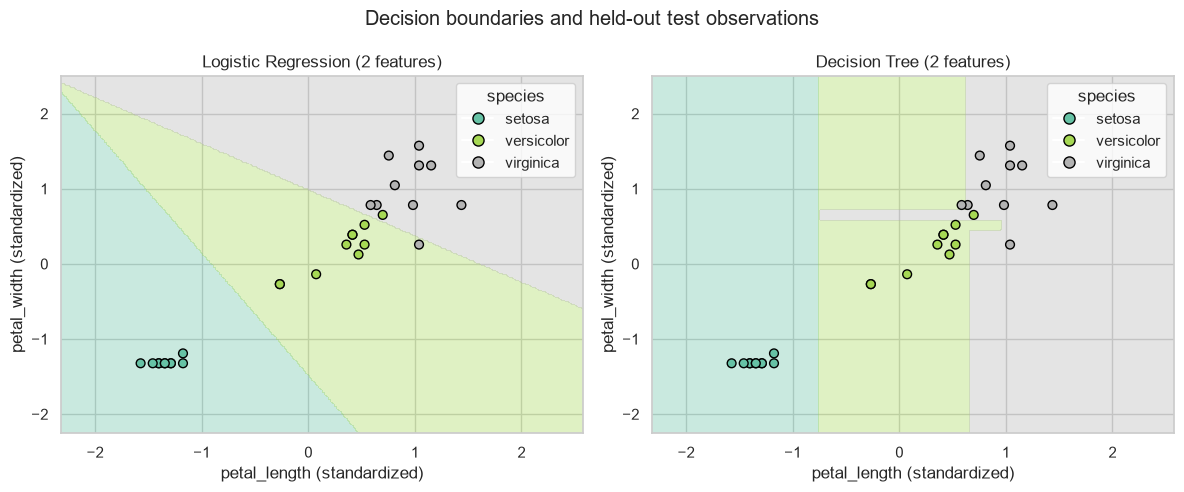

In [24]:
x_min, x_max = X_boundary_train[:, 0].min() - 0.8, X_boundary_train[:, 0].max() + 0.8
y_min, y_max = X_boundary_train[:, 1].min() - 0.8, X_boundary_train[:, 1].max() + 0.8
mesh_x, mesh_y = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))
grid = np.c_[mesh_x.ravel(), mesh_y.ravel()]
class_to_number = {label: index for index, label in enumerate(labels)}
class_cmap = plt.get_cmap("Set2", len(labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, model, title in [
    (axes[0], logistic_boundary_model, "Logistic Regression"),
    (axes[1], tree_boundary_model, "Decision Tree"),
]:
    grid_predictions = model.predict(grid)
    regions = np.array([class_to_number[label] for label in grid_predictions]).reshape(mesh_x.shape)
    ax.contourf(
        mesh_x, mesh_y, regions,
        levels=np.arange(-0.5, len(labels) + 0.5, 1),
        cmap=class_cmap, alpha=0.35,
    )
    test_numbers = np.array([class_to_number[label] for label in y_test])
    ax.scatter(
        X_boundary_test[:, 0], X_boundary_test[:, 1],
        c=test_numbers, cmap=class_cmap, edgecolor="black", s=40,
    )
    ax.set_title(f"{title} (2 features)")
    ax.set_xlabel(f"{boundary_features[0]} (standardized)")
    ax.set_ylabel(f"{boundary_features[1]} (standardized)")
    legend_handles = [
        plt.Line2D([0], [0], marker="o", color="w", label=label,
                   markerfacecolor=class_cmap(index), markeredgecolor="black", markersize=8)
        for label, index in class_to_number.items()
    ]
    ax.legend(handles=legend_handles, title=target)

plt.suptitle("Decision boundaries and held-out test observations")
plt.tight_layout()
plt.show()

## Conclusion

The printed comparison is based on the held-out test rows. I interpret the score together with the per-class report and confusion matrices rather than relying on accuracy alone. The 2D boundary figure is a visual aid and is not the evaluation result for the full-feature models.

In [25]:
print("The comparison above uses the same stratified 80/20 split for both classifiers.")
print("Interpret the test metrics and confusion matrices together when discussing model performance.")
print(f"The original dataset remains at: {dataset_path}")

The comparison above uses the same stratified 80/20 split for both classifiers.
Interpret the test metrics and confusion matrices together when discussing model performance.
The original dataset remains at: C:\Users\usms.202300087\Datheon_Machine_Learning_&_Data_Science_Internship\Task 1\iris.csv


## Project reflection

On the executed 80/20 split, both full-feature models achieved **0.933 accuracy** and **0.933 weighted F1**. The class report shows perfect scores for *setosa* and 0.90 precision, recall, and F1 for both *versicolor* and *virginica*. Since the two models tied on the reported aggregate metrics, this experiment does not show that one is universally better.

The result is based on a single train/test split, so it may vary with another split. For a stronger comparison, I would repeat evaluation with stratified cross-validation and report the mean and variation of the scores. The decision-boundary figures use only `petal_length` and `petal_width`; they help explain a two-dimensional view but do not replace the four-feature evaluation.

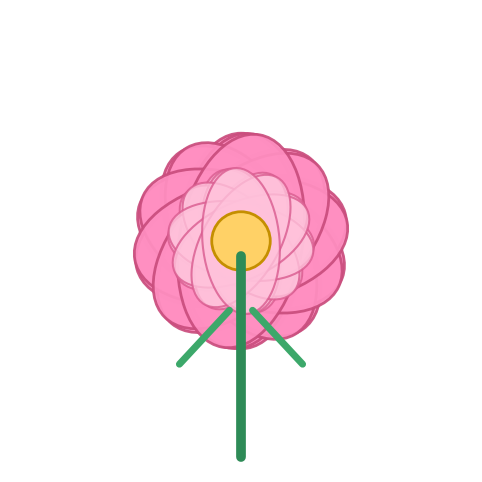

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, Circle

fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
ax.set_aspect('equal')
ax.axis('off')

# Outer open petals
for angle in range(0, 360, 35):
    petal = Ellipse(
        (0, 0),
        width=1.6,
        height=2.8,
        angle=angle,
        facecolor='#ff8fc1',     # pink
        edgecolor='#c94d7d',
        linewidth=2,
        alpha=0.92
    )
    ax.add_patch(petal)

# Inner small petals to make it look more open
for angle in range(15, 375, 35):
    petal = Ellipse(
        (0, 0),
        width=1.0,
        height=1.9,
        angle=angle,
        facecolor='#ffc2db',
        edgecolor='#d95b8f',
        linewidth=1.5,
        alpha=0.8
    )
    ax.add_patch(petal)

# Center
ax.add_patch(Circle((0, 0), 0.38, facecolor='#ffd166',
                   edgecolor='#c58f00', linewidth=2))

# Stem and leaves
ax.plot([0, 0], [-2.8, -0.2], color='#2e8b57', linewidth=7)
ax.plot([-0.8, -0.15], [-1.6, -0.9], color="#15e971", linewidth=5)
ax.plot([0.8, 0.15], [-1.6, -0.9], color='#3ca86a', linewidth=5)

plt.show()